# Geometric & Contextual QA Checks

Runs a suite of quality checks on a standardized ground-truth dataset (the
output of `preprocessing_notebook.ipynb`) before it's considered ready to
ship: geometry validity/repair, size and shape anomalies, a crop-mask
(land-cover) sanity check against ESA WorldCover, proximity to roads, and
overlapping field boundaries.

## Expected Inputs
- Standardized geometry file: output of `preprocessing_notebook.ipynb`
  (e.g. `data/check_file.geojson`), with `Geom_id`, `Season_id`, `Src_id`
  and `geometry` at minimum.
- Internet access: land-cover checks call the Microsoft Planetary
  Computer STAC API; road checks call OpenStreetMap via `osmnx`.

## Sections
1. Load Data
2. Geometry & CRS Checks (validity, repair, size/shape anomalies, disconnected multipolygons)
3. Land Cover / Crop Mask Checks (Planetary Computer / ESA WorldCover)
4. Road Proximity Checks (OpenStreetMap via osmnx)
5. Overlap Detection (self-intersecting field boundaries)

## Output
This notebook is a diagnostic pass — it doesn't write a file. Flagged rows
(size/aspect-ratio anomalies, high `Bad_LC_Fraction`, high `overlap_ratio`,
etc.) should be reviewed manually before any rows are dropped or
geometries edited.

## Known limitations
- Road checks fetch data live per run. For country-scale datasets this can
  be slow — a 15-field/~30km test cluster alone took ~70s just for the OSM
  road-graph fetch. Batch by region/tile rather than running the full
  extent at once for large datasets.
- The overlap-detection section keys off `Src_id`, which only ends up in
  `check_file.geojson` if it was mapped in `preprocessing_notebook.ipynb`'s
  "Confirm Mapping" step (manually in the UI, or via `.confirm()` for a
  headless run).

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import xarray as xr
from shapely.geometry import Polygon
import matplotlib.pyplot as plt
import sys
from datetime import datetime
import utils
import scripts.crop_type
import scripts.geom_processing
import scripts.observation_processing
import scripts.automation
import ipywidgets as widgets
from IPython.display import display
import geopandas as gpd
import pandas as pd
import utils
import itertools
from pystac_client import Client
import planetary_computer
import rasterio
from rasterio.mask import mask
from shapely.ops import split
from rasterio.merge import merge
from rasterstats import zonal_stats
from shapely.geometry import box
import osmnx as ox


from utils import crop_variations, season_codes, variation_codes, group_codes #, crop_codes, database_schema
from scripts.crop_type import map_variations, code_variations, parse_crop_type, add_crop_code
from scripts.geom_processing import check_invalid_geoms, check_repeating_geoms, check_repeating_geoms_s2cell
from scripts.observation_processing import to_datetime,to_numeric,assign_date,yield_process

#sys.path.append('..')

## 1. Load Data

In [2]:
df = gpd.read_file("data/check_file.geojson")
df2 = gpd.read_parquet("data/2023_kernel.parquet")
df.head()

,Geom_id,Season_id,Sow_Year,Est_Sow_Year,Src_id,Src_File,Provider,Crop,Crop_Season,Crop_Group,Crop_Variation,Sow_Date,Sow_Day,Yield,geometry
0,40d74a3f67010c,40d74a3f67010c-2023_EST,NaN,2023.0,0,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Grassland,NaN,Non Crop,None,NaT,NaN,NaN,"POLYGON ((33.20118 49.19568, 33.20114 49.19569..."
1,40d6888749dff4,40d6888749dff4-2023_EST,NaN,2023.0,1,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Grassland,NaN,Non Crop,None,NaT,NaN,NaN,"POLYGON ((32.61933 49.99669, 32.61914 49.99669..."
2,40d5c94c4f5fbc,40d5c94c4f5fbc-2023-04-17,2023.0,NaN,10,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Grassland,NaN,Non Crop,None,2023-04-17,17.0,NaN,"POLYGON ((32.17066 50.28364, 32.17068 50.28369..."
3,40d60d3023aa1c,40d60d3023aa1c-2023-05-14,2023.0,NaN,1000,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Soybean,NaN,Legumes/Pulses,None,2023-05-14,14.0,NaN,"MULTIPOLYGON (((32.9605 50.31382, 32.9603 50.3..."
4,40d60d359155cc,40d60d359155cc-2023-05-12,2023.0,NaN,1001,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Soybean,NaN,Legumes/Pulses,None,2023-05-12,12.0,NaN,"POLYGON ((32.96351 50.30416, 32.96315 50.30419..."


## 2. Geometry & CRS Checks

Null/invalid geometry check, CRS check, `make_valid` repair, size and
aspect-ratio anomaly detection, and disconnected-multipolygon flagging.

In [ ]:
# Check the invalid geometries 

invalid_check = scripts.geom_processing.check_invalid_geoms(df)    

No invalid geoms


In [ ]:
import shapely

def check_null_geoms(gdf:gpd.GeoDataFrame):
    """
    Checks and separates null geometries from a GeoDataFrame.

    Args:
        gdf (gpd.GeoDataFrame) : Input GeoDataFrame.

    Returns:
        tuple: (invalid_geometries_gdf, valid_geometries_gdf)

    Raises:
        TypeError: If input is not a GeoDataFrame
        ValueError: If 'geometry' column is missing

    """
    if not isinstance(gdf, gpd.GeoDataFrame):
        raise TypeError("Input must be a GeoDataFrame")
    if 'geometry' not in gdf.columns:
        raise ValueError("Input GeoDataFrame must have a 'geometry' column")

    invalid_geoms = gdf[~gdf.geometry.notnull()]
    valid_geoms = gdf[gdf.geometry.notnull()].copy().reset_index(drop=True)
    
    if invalid_geoms.empty:
        print("No invalid geoms")
    else:
        print("The invalid geoms are: ",invalid_geoms)
    return invalid_geoms,valid_geoms


def valid_crs(gdf:gpd.GeoDataFrame, target_crs:str):
    """
    Checks if the dataset is in the target reference system
    
    Args:
        1. gdf (gpd.GeoDataFrame) : Input GeoDataFrame.
        2. Target crs (e.g. "EPSG:4326")
    
    Returns:
        True: If the dataset is the in the target crs.
        False: If the dtaaset is not in the target crs.
    
    """
    if gdf.crs is None:
        print("Dataset has no CRS defined")
        return False
    
    current = gdf.crs.to_string()
    
    if current != target_crs:
        print("CRS mismatch")
        print(f"Current CRS {current}")
        print(f"Expected CRS: {target_crs}")
        return False
    else: 
        print(f"The CRS is correct: {current}")
        return True
        

def make_valid_geoms(gdf:gpd.GeoDataFrame):
    """
    Uses shapely.make_valid to resolve geometries
    
    Args:
        gdf (gpd.GeoDataFrame) : Input GeoDataFrame.
    
    Returns:
        gdf (gpd.GeoDataFrame) : GeoDataFrame with valid geoms.
    """
    gdf["geometry"] = gdf["geometry"].apply(shapely.make_valid)
    print("All geometries have been resolved")
    return gdf        


def get_utm_crs(gdf:gpd.GeoDataFrame):
    """
    Calculates the valid UTM CRS for geometries to perform area calculations
    
    Args:
        gdf (gpd.GeoDataFrame) : Input GeoDataFrame.
        
    Returns:
        str : UTM CRS for the region where the dataframe lies.
    """

    if gdf.crs is None:
        raise ValueError("GeoDataFrame has no CRS defined.")

    gdf_4326 = gdf.to_crs("EPSG:4326")

    centroid = gdf_4326.unary_union.centroid
    lon, lat = centroid.x, centroid.y

    zone = int((lon + 180) / 6) + 1

    if lat >= 0:
        epsg = 32600 + zone
    else:
        epsg = 32700 + zone

    return f"EPSG:{epsg}"

def detect_polygon_size_anomaly(
    gdf:gpd.GeoDataFrame,
    upper_limit:float=10000,
    lower_limit:float=5
    ):
    """
    Removes fields that are either too big or too small
    
    Args:
        1. gdf (gpd.GeoDataFrame) : Input GeoDataFrame containing the polygons.
        2. upper_limit (float, optional) : Maximum allowed area in hectares. Defaults to 10000.
        3. lower_limit (float, optional) : Minimum allowed are in hectares. Defaults to 5.
    
    Returns:
        gpd.GeoDataFrame : A clean GeoDataFrame with anomolous fields removed.
    
    """
    utm_crs = get_utm_crs(gdf)
    gdf_proj = gdf.to_crs(utm_crs)
    gdf_proj["Area_ha"] = gdf_proj.area / 10000
    #print("Area statistics:")
    #print(gdf_proj["Area_ha"].describe())
    anomalies = (
        (gdf_proj["Area_ha"] > upper_limit) | 
        (gdf_proj["Area_ha"] < lower_limit)
        )
    removed_count = anomalies.sum()
    gdf_clean = gdf.loc[~anomalies]
    print(f"{removed_count} polygons removed")
        
    return gdf_clean


def compute_aspect_ratio(gdf:gpd.GeoDataFrame):
    """
    Calcualates the aspect ratio for the minimum rotated rectange for each polygon.
    
    The aspect ratio is determined by finding the minimum bounding rotated rectangle 
    for each geometry and calculating the ratio of its length to its width using np.linalg.norm.
    
    Notes:
        - Aspect Ratio < 1.1 indicates a geometry that is nearly square.
        - Aspect Ratio > 20 indicates a geometry that is highly elongated. 
      
    Args:
        gdf (gpd.GeoDataFrame) : Input GeoDataFrame containing the polygons.
        
    Returns: 
        gpd.GeoDataFrame: Original GeoDataFrame with a new "Aspect_Ratio" column.
    
    """ 
    utm_crs = get_utm_crs(gdf)
    gdf_proj = gdf.to_crs(utm_crs)
    
    aspect_ratios = []
    
    for geom in gdf_proj.geometry:
        if geom.is_empty:
            aspect_ratios.append(np.nan)
            continue
        
        mrr = geom.minimum_rotated_rectangle
        coords = list(mrr.exterior.coords)
        
        edges = [
            np.linalg.norm(
                np.array(coords[i]) - np.array(coords[i+1])
            )
            for i in range(4)
        ] 
        width = min(edges)
        height = max(edges)   
        
        if width == 0:
            aspect_ratios.append(np.nan)
        else:
            aspect_ratios.append(height/width)
    gdf["Aspect_Ratio"] = aspect_ratios
    
    return gdf





def flag_disconnected_multipolygons(gdf:gpd.GeoDataFrame, threshold:float=100):
    """
    Flags polygons within a multipolygon to flag any disconnect multipolygons.
 
    Args:
        gdf (gpd.GeoDataFrame) : Input GeoDataFrame containing the polygons.
        threshold (float, optional) : Threshold distance 
        
    Returns: 
        gpd.GeoDataFrame: Original GeoDataFrame with a new "Disconnected_Multi" column.
    
    """
    gdf = gdf.to_crs(get_utm_crs(gdf))
    flags = []

    for geom in gdf.geometry:
        if geom.geom_type != "MultiPolygon":
            flags.append(False)
            continue

        parts = list(geom.geoms) #creates a list of polygons from Multi-polygons 
        min_dist = min(
            a.distance(b)
            for a, b in itertools.combinations(parts, 2)
        )
        flags.append(min_dist > threshold)

    gdf["Disconnected_Multi"] = flags
    return gdf

import geopandas as gpd

def calculate_multipolygon_separation(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    """Calculates the maximum separation gap between parts of a MultiPolygon.
    
    Args:
        gdf (gpd.GeoDataFrame): Input GeoDataFrame.
        
    Returns:
        gpd.GeoDataFrame: Original dataframe with a new 'Max_Separation_m' column.
    """
    # Ensure projected CRS for accurate meter calculations
    gdf = gdf.to_crs(get_utm_crs(gdf))
    distances = []

    for geom in gdf.geometry:
        # If it's not a MultiPolygon (or only has 1 part), separation is 0
        if geom.geom_type != "MultiPolygon" or len(geom.geoms) < 2:
            distances.append(0.0)
            continue

        parts = list(geom.geoms)
        part_min_distances = []
        
        # For each part, find how far away its CLOSEST sibling is
        for i, part in enumerate(parts):
            other_parts = [p for j, p in enumerate(parts) if j != i]
            min_dist_to_others = min(part.distance(other) for other in other_parts)
            part_min_distances.append(min_dist_to_others)
            
        # The true separation of the MultiPolygon is the largest gap 
        max_gap = max(part_min_distances)
        distances.append(max_gap)

    # Return the VALUE, not the flag!
    gdf["Max_Separation_m"] = distances
    gdf["Max_Separation_m"] = gdf["Max_Separation_m"].round(2)
    
    return gdf

In [ ]:
c = make_valid_geoms(df)
b = valid_crs(df,'EPSG:4326')
#get_utm_crs(df)
x = detect_polygon_size_anomaly(df)

ar = compute_aspect_ratio(df)
x1 = scripts.geom_processing.check_repeating_geoms(df2)
fl = flag_disconnected_multipolygons(df2,threshold=1000)

All geometries have been resolved
The CRS is correct: EPSG:4326


C:\Users\gmana\AppData\Local\Temp\ipykernel_43268\3005057439.py:31: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf_4326.unary_union.centroid


Area statistics:
count    2134.000000
mean       94.899170
std        68.785288
min         6.990069
25%        46.792693
50%        77.711237
75%       121.511668
max       726.217137
Name: Area_ha, dtype: float64
0 polygons removed


C:\Users\gmana\AppData\Local\Temp\ipykernel_43268\3005057439.py:31: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf_4326.unary_union.centroid


## 3. Land Cover / Crop Mask Checks

Flags the fraction of each field that falls on non-cropland (forest,
built-up, water) using ESA WorldCover via the Microsoft Planetary Computer
STAC API. Requires internet access.

In [ ]:
#items

def fetch_mpc_collection(aoi_bbox:list, collection:str="esa-worldcover", **kwargs):
    """
    Fetches items from the Microsoft Planetary Computer STAC catalog.
    
    Args: 
        1. aoi_bbox (list): Bounding box coordinates [minx, miny, maxx, maxy].
        2. collection (str, optional): The STAC collection ID. Defaults to "esa-worldcover".
        **kwargs: Any additional parameters supported by pystac_client.search()
                    (e.g., datetime, query, limit, intersects).
    Returns:
        list: A list of STAC items    
    """
    catalog = Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1"
    )
    search = catalog.search(
        collections = [collection],
        bbox = aoi_bbox,
        **kwargs
    )
    items = list(search.items())
    
    return items


def compute_landcover_flags(gdf:gpd.GeoDataFrame, items:list, 
                            bad_classes:list=[10, 50, 80],  # forest, built-up, water
                            stac_key:str="map"):
    """
    Calculate the fraction of a polygon that doesn't fall on cropland. 
    Default parameters set for esa-worldcover if worldcover STAC items are passed
    
    Args:
        1. gdf (gpd.GeoDataFrame): Input GeoDataFrame.
        2. items (list): Landcover STAC items
        3. bad_classes (list, optional): List of integer pixel values to flag. Defaults to [10,50,80] (esa-worldcover classes - forest, built-up, water)
        4. stac_key (str, optional): The STAC asset key containing the raster data. Defaults to "map" for esa-worldcover
    
    Returns:
        gpd.GeoDataFrame: Original dataframe with a new 'Bad_LC_Fraction' column.
    """

    gdf_4326 = gdf.to_crs("EPSG:4326").copy()
    gdf_4326["total_pixels"] = 0
    gdf_4326["bad_pixels"] = 0

    for item in items:

        signed_url = planetary_computer.sign(item.assets[stac_key].href)

        with rasterio.open(signed_url) as src:

            tile_bbox = box(*src.bounds)
            intersecting = gdf_4326[gdf_4326.intersects(tile_bbox)]

            if intersecting.empty:
                continue

            stats = zonal_stats(
                intersecting,
                signed_url,
                categorical=True,
                nodata=0
            )

            for idx, stat in zip(intersecting.index, stats):

                if stat is None:
                    continue

                total = sum(stat.values())
                bad = sum(stat.get(cls, 0) for cls in bad_classes)

                gdf_4326.loc[idx, "total_pixels"] += total
                gdf_4326.loc[idx, "bad_pixels"] += bad

    # Compute fraction
    gdf_4326["Bad_LC_Fraction"] = np.where(
        gdf_4326["total_pixels"] > 0,
        gdf_4326["bad_pixels"] / gdf_4326["total_pixels"],
        0
    )

    return gdf_4326.drop(columns=["total_pixels", "bad_pixels"])


In [126]:
df_4326 = df.to_crs("EPSG:4326")
items = fetch_mpc_collection(aoi_bbox=list(df_4326.total_bounds))
items#.head()


y = compute_landcover_flags(df,items)
y

,Geom_id,Season_id,Sow_Year,Est_Sow_Year,Src_id,Src_File,Provider,Crop,Crop_Season,Crop_Group,Crop_Variation,Sow_Date,Sow_Day,Yield,geometry,Bad_LC_Fraction
0,40d74a3f67010c,40d74a3f67010c-2023_EST,NaN,2023.0,0,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Grassland,NaN,Non Crop,None,NaT,NaN,NaN,"POLYGON ((33.20118 49.19568, 33.20114 49.19569...",0.002594
1,40d6888749dff4,40d6888749dff4-2023_EST,NaN,2023.0,1,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Grassland,NaN,Non Crop,None,NaT,NaN,NaN,"POLYGON ((32.61933 49.99669, 32.61914 49.99669...",0.003255
2,40d5c94c4f5fbc,40d5c94c4f5fbc-2023-04-17,2023.0,NaN,10,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Grassland,NaN,Non Crop,None,2023-04-17,17.0,NaN,"POLYGON ((32.17066 50.28364, 32.17068 50.28369...",0.000458
3,40d60d3023aa1c,40d60d3023aa1c-2023-05-14,2023.0,NaN,1000,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Soybean,NaN,Legumes/Pulses,None,2023-05-14,14.0,NaN,"MULTIPOLYGON (((32.9605 50.31382, 32.9603 50.3...",0.002225
4,40d60d359155cc,40d60d359155cc-2023-05-12,2023.0,NaN,1001,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Soybean,NaN,Legumes/Pulses,None,2023-05-12,12.0,NaN,"POLYGON ((32.96351 50.30416, 32.96315 50.30419...",0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2129,412a9c28c98124,412a9c28c98124-2023-05-10,2023.0,NaN,995,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Soybean,NaN,Legumes/Pulses,None,2023-05-10,10.0,NaN,"MULTIPOLYGON (((31.87617 51.06197, 31.8765 51....",0.000219
2130,40d60d4c74765c,40d60d4c74765c-2023-05-12,2023.0,NaN,996,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Soybean,NaN,Legumes/Pulses,None,2023-05-12,12.0,NaN,"POLYGON ((32.97741 50.30315, 32.97722 50.30315...",0.007927
2131,40d60d43bef3d4,40d60d43bef3d4-2023-05-11,2023.0,NaN,997,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Soybean,NaN,Legumes/Pulses,None,2023-05-11,11.0,NaN,"MULTIPOLYGON (((32.98048 50.31161, 32.98027 50...",0.000368
2132,40d60d402d1754,40d60d402d1754-2023-05-11,2023.0,NaN,998,data/2023_kernel.parquet + data/2023_kernel_ta...,ExampleProvider,Soybean,NaN,Legumes/Pulses,None,2023-05-11,11.0,NaN,"POLYGON ((32.98707 50.31472, 32.98688 50.31474...",0.026263


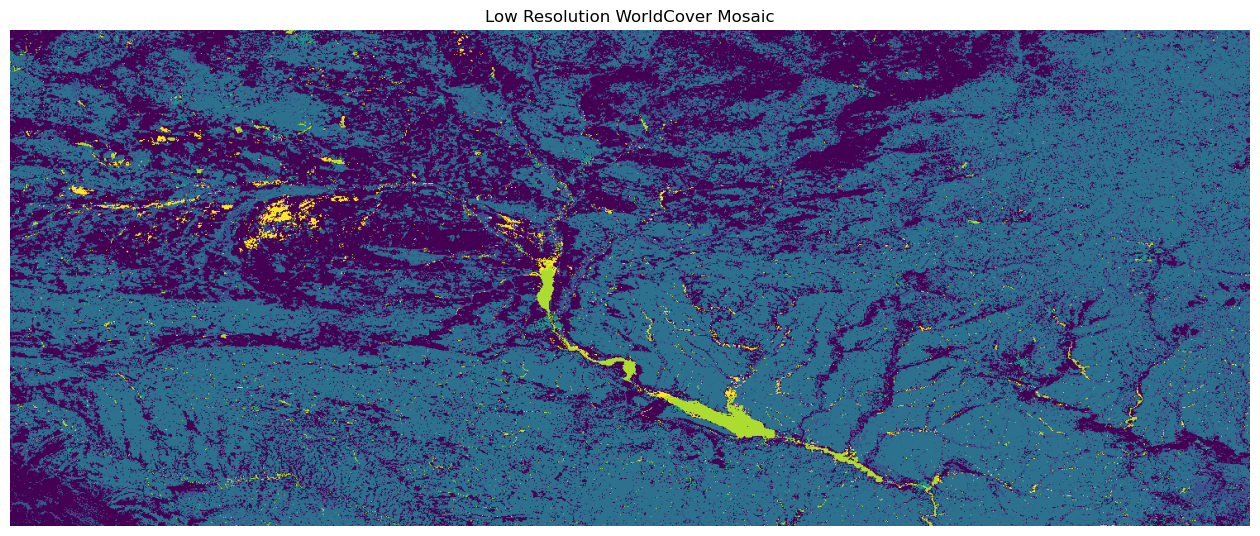

In [128]:
import rasterio
from rasterio.merge import merge
import matplotlib.pyplot as plt

#item = items[0]
#
#asset = item.assets["map"]
#
signed_urls = [
    planetary_computer.sign(item.assets["map"].href)
    for item in items
]
#
#src_files = [rasterio.open(url) for url in signed_urls]


datasets = []

for url in signed_urls:
    src = rasterio.open(url)
    datasets.append(src)

# Merge at low resolution automatically
mosaic, transform = merge(
    datasets,
    res=(0.01, 0.01)  # coarser resolution in degrees (adjust if needed)
)
plt.figure(figsize=(16,8))
plt.imshow(mosaic[0])
plt.title("Low Resolution WorldCover Mosaic")
plt.axis("off")
plt.show()

## 4. Road Proximity Checks

Fetches the OSM road network (via `osmnx`) for the dataset's extent and
flags fields that sit exactly on a road, or whose polygon is split by one.
Requires internet access, and can be slow for large/country-scale extents
— see the note at the top of this notebook.

In [3]:
import osmnx as ox 

gdf_4326 = df.to_crs("EPSG:4326")
buffered = gdf_4326.buffer(0.01)  # ~1km in degrees (rough approx)
aoi_small = buffered.union_all()

roads = ox.graph_from_polygon(
    aoi_small,
    network_type="drive"
)

C:\Users\gmana\AppData\Local\Temp\ipykernel_53880\1596088772.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  buffered = gdf_4326.buffer(0.01)  # ~1km in degrees (rough approx)
c:\Users\gmana\anaconda3\envs\fresh_test\Lib\site-packages\osmnx\_overpass.py:271: UserWarning: This area is 91 times your configured Overpass max query area size. It will automatically be divided up into multiple sub-queries accordingly. This may take a long time.
  multi_poly_proj = utils_geo._consolidate_subdivide_geometry(poly_proj)


In [ ]:
import osmnx as ox 

gdf_4326 = df.to_crs("EPSG:4326")
minx, miny, maxx, maxy = gdf_4326.total_bounds
gdf_4326 = gdf_4326.iloc[:10]
roads = ox.graph_from_bbox(
    (maxy,miny,maxx,minx),
    network_type="drive"
)

roads_gdf = ox.graph_to_gdfs(roads, nodes=False)

c:\Users\gmana\anaconda3\envs\fresh_test\Lib\site-packages\osmnx\_overpass.py:271: UserWarning: This area is 1,282 times your configured Overpass max query area size. It will automatically be divided up into multiple sub-queries accordingly. This may take a long time.
  multi_poly_proj = utils_geo._consolidate_subdivide_geometry(poly_proj)


In [ ]:
def fetch_osm_roads(
  bbox: list,
  road_types: list = None
):
  """
  Fetches road geometries from OpenStreetMap, via osmnx's Overpass client
  (same backend as the road-network graph above, but osmnx handles
  query-splitting/retries more reliably than a raw request to the endpoint).

  Args:
    1. bbox (list): Bounding box coordinates in [minx, miny, maxx, maxy] format.
    2. road_types (list, optional): List of OSM highway types to keep. Defaults to major roads.

  Returns:
    gpd.GeoDataFrame: Road geometries with their highway classifications.

  """

  if road_types is None:
    road_types = ["motorway","trunk","primary","secondary","tertiary"]

  minx, miny, maxx, maxy = bbox

  graph = ox.graph_from_bbox((maxy, miny, maxx, minx), network_type="drive")
  edges = ox.graph_to_gdfs(graph, nodes=False).reset_index(drop=True)

  # 'highway' can be a single tag or a list of tags per edge; keep the first tag
  edges["highway"] = edges["highway"].apply(lambda h: h[0] if isinstance(h, list) else h)
  roads_gdf = edges[edges["highway"].isin(road_types)][["highway", "geometry"]].reset_index(drop=True)

  if roads_gdf.empty:
    print("No roads found in this bounding box for the specified types.")

  return roads_gdf




gdf_4326_small = df#.iloc[:1000]


# bounding box from your polygons

gdf_4326 = gdf_4326_small.to_crs("EPSG:4326")
minx, miny, maxx, maxy = gdf_4326.total_bounds


df_major_roads = fetch_osm_roads(bbox=df.total_bounds)
df_major_roads


In [ ]:
utm_crs = get_utm_crs(df)
gdf_proj = df.to_crs(utm_crs)
roads_proj = df_major_roads.to_crs(utm_crs)
gdf_with_roads = gpd.sjoin_nearest(
    gdf_proj, 
    roads_proj, 
    how="left", 
    distance_col="dist_to_road_m"
)
gdf_clean = gdf_with_roads[~gdf_with_roads.index.duplicated(keep="first")]

check_split = gdf_clean[gdf_clean["dist_to_road_m"] == 0]
check_split.head()

In [ ]:
#optional
def road_split_metric(geom, roads):

    parts = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]

    ratios = []

    for part in parts:

        road_inside = roads.intersection(part)

        if road_inside.is_empty:
            continue

        try:
            pieces = split(part, road_inside)

            if len(pieces.geoms) > 1:

                areas = [p.area for p in pieces.geoms]
                ratios.append(min(areas) / part.area)

        except:
            pass

    return max(ratios) if ratios else 0

road_union = roads_proj.union_all()
check_split["ratio"] = check_split.geometry.apply(
    lambda g: road_split_metric(g, road_union)
    )
check_split[check_split["ratio"]>0.5]

## 5. Overlap Detection

Finds pairs of field boundaries in the dataset that spatially overlap
(self-intersections within the dataset) and reports the overlap ratio, so
significantly-overlapping fields can be reviewed. `get_significant_overlaps`
is the reusable, parametrized version of this check.

In [74]:
import geopandas as gpd

# 1. Spatial Join & Remove self-intersections
poly_intersect = gpd.sjoin(
    gdf_proj[["Geom_id","Season_id","geometry","Src_id"]],
    gdf_proj[["Geom_id","Season_id","geometry","Src_id"]],
    how="inner",
    predicate="intersects"
)  
poly_intersect = poly_intersect[poly_intersect.index != poly_intersect["index_right"]]

# 2. Extract Right Geometries AND Align the Index (CRITICAL FIX)
right_geometries = gdf_proj.geometry.loc[poly_intersect["index_right"]]
right_geometries.index = poly_intersect.index 

# 3. Perform Vectorized Intersection
poly_intersect["intersection_geom"] = poly_intersect.geometry.intersection(right_geometries)

# 4. Calculate Areas DIRECTLY from the explicit columns (Safest Method)
# (poly_intersect.geometry is still natively the Left Geometry from the sjoin)
poly_intersect["area_left"] = poly_intersect.geometry.area 
poly_intersect["area_right"] = right_geometries.area
poly_intersect["overlap_area"] = poly_intersect["intersection_geom"].area

# 5. Calculate Overlap Ratio
poly_intersect["overlap_ratio"] = (
    poly_intersect["overlap_area"] /
    poly_intersect[["area_left","area_right"]].min(axis=1)
)#.round(2)

# 6. Deduplicate A-B and B-A pairs
poly_intersect = poly_intersect[poly_intersect.index < poly_intersect["index_right"]]
poly_intersect
##road_split_metric()
##road_split_metric

,Geom_id_left,Season_id_left,geometry,Src_id_left,index_right,Geom_id_right,Season_id_right,Src_id_right,intersection_geom,area_left,area_right,overlap_area,overlap_ratio
978,46d5121c24249c,46d5121c24249c-2023-04-29,"POLYGON ((358683.867 5735197.578, 358733.193 5...",231,1163,46d5121b96f2fc,46d5121b96f2fc-2023_EST,256,"POLYGON ((357308.769 5734490.283, 357268.687 5...",2.592047e+06,2.192054e+05,219205.417926,1.000000e+00
1610,40d9f3c590387c,40d9f3c590387c-2022-10-31,"POLYGON ((575576.757 5425639.736, 575548.334 5...",467,1818,40d9f3c6178f9c,40d9f3c6178f9c-2022-08-11,712,"MULTILINESTRING ((574997.981 5424266.109, 5750...",2.534733e+05,6.572246e+05,0.000000,0.000000e+00
1973,40d5e01a4d4c7c,40d5e01a4d4c7c-2023-05-10,"POLYGON ((483784.998 5581438.665, 483780.5 558...",854,1977,40d60a9dd94c84,40d60a9dd94c84-2023-05-12,858,"POLYGON ((483881.528 5581361.717, 483881.955 5...",1.424790e+06,2.624084e+06,0.779575,5.471505e-07


In [36]:
import geopandas as gpd

def get_significant_overlaps(gdf:gpd.GeoDataFrame, keep_cols:list=None, threshold:float=0.10):
    
    target_crs = get_utm_crs(gdf=gdf)
    gdf = gdf.to_crs(target_crs)
    
    if keep_cols:
        safe_cols = list(set(keep_cols + [gdf.geometry.name]))
        work_gdf = gdf[safe_cols]
    else:
        work_gdf = gdf
    
    # 1. Spatial Join & Remove self-intersections
    poly_intersect = gpd.sjoin(work_gdf, 
                               work_gdf, 
                               how="inner", 
                               predicate="intersects")  
    poly_intersect = poly_intersect[poly_intersect.index < poly_intersect["index_right"]].copy()
    
    
    
    if poly_intersect.empty:
        print("No overlaps found.")
        return poly_intersect

    # 2. Extract Right Geometries AND Align the Index
    right_geometries = gdf.geometry.loc[poly_intersect["index_right"]]
    right_geometries.index = poly_intersect.index 

    # 3. Perform Vectorized Intersection
    poly_intersect["intersection_geom"] = poly_intersect.geometry.intersection(right_geometries)

    # 4. Calculate Areas DIRECTLY
    poly_intersect["area_left"] = poly_intersect.geometry.area 
    poly_intersect["area_right"] = right_geometries.area
    poly_intersect["overlap_area"] = poly_intersect["intersection_geom"].area

    # 5. NEW: Calculate the specific overlap percentage for BOTH polygons
    poly_intersect["pct_overlap_left"] = (poly_intersect["overlap_area"] / poly_intersect["area_left"]).round(4)
    poly_intersect["pct_overlap_right"] = (poly_intersect["overlap_area"] / poly_intersect["area_right"]).round(4)

    # 6. Calculate Maximum Overlap Ratio (for the threshold filter)
    poly_intersect["max_overlap_ratio"] = (
        poly_intersect["overlap_area"] /
        poly_intersect[["area_left","area_right"]].min(axis=1)
    ).round(4)
        
    # 8. Filter by the user-defined threshold (using the max ratio)
    filtered_overlaps = poly_intersect[poly_intersect["max_overlap_ratio"] > threshold]
    
    return filtered_overlaps

x = get_significant_overlaps(gdf=gdf_proj, threshold=0.1, keep_cols=["Geom_id","Season_id","Src_id"])
x

C:\Users\gmana\AppData\Local\Temp\ipykernel_43620\4062892820.py:91: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf_4326.unary_union.centroid


,Src_id_left,Geom_id_left,geometry,Season_id_left,index_right,Src_id_right,Geom_id_right,Season_id_right,intersection_geom,area_left,area_right,overlap_area,pct_overlap_left,pct_overlap_right,max_overlap_ratio
978,231,46d5121c24249c,"POLYGON ((358683.867 5735197.578, 358733.193 5...",46d5121c24249c-2023-04-29,1163,256,46d5121b96f2fc,46d5121b96f2fc-2023_EST,"POLYGON ((357308.769 5734490.283, 357268.687 5...",2.592047e+06,219205.417926,219205.417926,0.0846,1.0,1.0
